# Schritt 3: Modellvergleich

**Ziel dieses Notebooks:** mit einer geeigneten Metrik entscheiden, welches Modell den Schadenbedarf pro Vertrag und
Jahr vorhersagen soll. Verglichen werden ein konstantes Modell, ein GLM und ein Gradient-Boosting-Modell, alle mit
denselben fünf Folds auf dem Trainingsteil. Der Testteil wird hier nicht benutzt.

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import PoissonRegressor, GammaRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_tweedie_deviance, d2_tweedie_score

pd.set_option("display.width", 200)   # show wide tables without cutting columns

## 1. Daten laden

In [2]:
# model table from step 2; only the training part is used in this notebook
df = pd.read_parquet("../data/model_data.parquet")
train = df[df["split"] == "train"]
print("training part:", len(train), "contracts |", round(train["Exposure"].sum()), "contract-years |",
      train["claim_rows"].sum(), "claims")

training part: 542410 contracts | 286899 contract-years | 21146 claims


## 2. Die Kandidaten

**The candidates**

All models predict the expected capped claim cost per contract-year as **frequency × severity** (step 2, section 3).

1. **Constant:** every contract pays the average cost per year of the fitting data. Every useful model must beat it.
2. **GLM (Poisson × Gamma):** the frequency with a Poisson GLM and the severity with a Gamma GLM, both with log link.
   The premium is a product of factors, one per band or category level: base × factor(Bonus-Malus band) × factor(age
   band) × ... It can be printed as a tariff table. The coefficients are maximum-likelihood estimates without penalty
   (`alpha=0`).
3. **GBM (Poisson × Gamma):** the same two parts, each a gradient boosting model (many small decision trees,
   scikit-learn `HistGradientBoostingRegressor`) with Poisson or Gamma loss. It learns the shapes and the interactions
   of the raw features itself, but it is not a table of factors.

Details of the code below:

* **Exposure as weight:** the frequency target is claims / exposure, with exposure as weight. For the Poisson
  likelihood with log link this gives the same estimates as the usual offset log(exposure): with y = N / E,
  Σ E · (y log μ − μ) = Σ (N log μ − E μ).
* **Severity:** the average capped claim of a contract, with the number of claims as weight.
* **GBM settings:** learning rate 0.05, at most 15 leaves per tree, at least 500 contracts per leaf for the frequency
  and 50 for the severity, a slight L2 penalty, early stopping on 10 % of the fitting data. They are fixed and not
  tuned; the aim is a fair comparison, not an extensive optimisation of many models.
* **Balance factor:** for each part one factor = actual total / predicted total on the fitting data. For a Poisson GLM
  with log link and an intercept, the maximum-likelihood equation of the intercept is Σ w (y − μ) = 0, so the predicted
  number of claims equals the actual one and the factor is exactly 1 (`tol=1e-6` solves the equations precisely enough
  for this). For the Gamma GLM it is close to 1. Boosting with early stopping does not have this property. The factor
  changes only the level of the premiums, not the order of the customers.

In [3]:
# GLM input: one 0/1 column per band or category level (the first level is the reference)
glm_cols = ["BonusMalusBand", "DrivAgeBand", "VehAgeBand", "VehPowerBand", "Area", "Region", "VehBrand", "VehGas"]

def glm_input(d):
    return pd.get_dummies(d[glm_cols], drop_first=True, dtype=float)

# GBM input: the raw values; the trees find the cut points themselves
gbm_cols = ["BonusMalus", "DrivAge", "VehAge", "VehPower", "Density", "Region", "VehBrand", "VehGas"]

def gbm_input(d):
    return d[gbm_cols]

print("GLM input:", glm_input(train).shape[1], "columns | GBM input:", gbm_input(train).shape[1], "columns")

GLM input: 58 columns | GBM input: 8 columns


In [4]:
# gradient boosting with modest, fixed settings (no tuning)
def boosting(loss, min_leaf):
    return HistGradientBoostingRegressor(loss=loss, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=min_leaf,
                                         l2_regularization=1.0, max_iter=1000, early_stopping=True,
                                         validation_fraction=0.1, n_iter_no_change=30,
                                         categorical_features="from_dtype", random_state=42)

def fit(kind, d):
    # frequency on all contracts (weight = exposure), severity on the contracts with a claim (weight = number of claims)
    if kind == "GLM":
        X = glm_input(d)
        freq = PoissonRegressor(alpha=0, solver="newton-cholesky", tol=1e-6)   # maximum likelihood, no penalty
        sev = GammaRegressor(alpha=0, solver="newton-cholesky", tol=1e-6)
    else:
        X = gbm_input(d)
        freq = boosting("poisson", 500)
        sev = boosting("gamma", 50)
    c = d["has_claim"].to_numpy()
    freq.fit(X, d["Frequency"], sample_weight=d["Exposure"])
    sev.fit(X[c], d["Severity"][c], sample_weight=d["claim_rows"][c])

    # balance: on the data it was fitted on, the model reproduces the total number of claims and the total claim cost
    k_freq = d["claim_rows"].sum() / (freq.predict(X) * d["Exposure"]).sum()
    k_sev = d["ClaimAmountCapped"][c].sum() / (sev.predict(X[c]) * d["claim_rows"][c]).sum()
    return {"kind": kind, "freq": freq, "sev": sev, "k_freq": k_freq, "k_sev": k_sev}

def predict(m, d):
    # expected capped claim cost per contract-year = frequency x severity
    X = glm_input(d) if m["kind"] == "GLM" else gbm_input(d)
    return m["k_freq"] * m["freq"].predict(X) * m["k_sev"] * m["sev"].predict(X)

## 3. Wie bewerte ich ein Modell?

**How I judge a model**

All metrics are computed on contracts that the model has not seen during fitting (cross-validation, section 4), on the
capped cost per contract-year, and weighted by exposure (step 1, section 10).

1. **Tweedie deviance with power 1.5: the decisive accuracy metric, lower is better.** 96 % of the contracts have no
   claim and a few have very high costs. If the number of claims is Poisson distributed and the claim sizes are Gamma
   distributed, the cost per year follows a Tweedie distribution with a power between 1 (Poisson) and 2 (Gamma): a
   point mass at 0 and a skewed positive part, exactly the shape of this target. 1.5 lies in between. The deviance is
   a consistent scoring function for the expected value: on average it is smallest for the true expected cost, so a
   model cannot improve it by predicting anything other than its best estimate (the same idea as a proper scoring rule
   such as the CRPS for whole distributions). The RMSE would be dominated by the few largest claims.
2. **D² (deviance explained):** 1 − deviance(model) / deviance(constant equal to the average of the evaluated data),
   like R². 0 = no better than the average, 1 = perfect. Whether a single contract has a claim in one year is mostly
   chance, so D² stays small; what counts is the comparison of the models on the same data.
3. **Gini (sorting):** the contracts are sorted from the cheapest to the most expensive prediction; the Lorenz curve
   shows which share of the actual cost falls on the cheapest x % of the exposure. Gini = 1 − 2 × the area under this
   curve: 0 = random order, higher = better sorting. It does not depend on the level of the premiums.
4. **Calibration (fairness):** predicted / actual total cost, and actual / predicted cost within groups of customers
   (age bands, Bonus-Malus bands, vehicle-age bands, areas, ten price groups). The goal is a fair premium for
   individual customers, so no group may pay systematically more or less than it costs.

**Decision rule:** the deviance decides between models that are equally well calibrated. The deviance is an average
over the whole portfolio, so systematic errors in small groups hardly change it. If the model with the lower deviance
prices whole groups of customers clearly wrong, it cannot set a fair premium, and the better calibrated model is
chosen.

In [5]:
def gini(y, mu, w):
    # Lorenz curve: contracts sorted from the lowest to the highest prediction
    order = np.argsort(np.asarray(mu))
    y, w = np.asarray(y)[order], np.asarray(w)[order]
    share_exposure = np.concatenate([[0], np.cumsum(w) / w.sum()])
    share_cost = np.concatenate([[0], np.cumsum(y * w) / (y * w).sum()])
    return 1 - 2 * np.trapezoid(share_cost, share_exposure)

def scores(d, mu, target="PurePremiumCapped"):
    y, w = d[target], d["Exposure"]
    return {"deviance": mean_tweedie_deviance(y, mu, sample_weight=w, power=1.5),
            "D2": d2_tweedie_score(y, mu, sample_weight=w, power=1.5),
            "gini": gini(y, mu, w) if np.ptp(mu) > 0 else np.nan,    # a constant premium does not sort anybody
            "predicted/actual": (mu * w).sum() / (y * w).sum()}

## 4. Kreuzvalidierung mit fünf Folds

In [6]:
# 5-fold cross-validation on the training part; the same folds for every model
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = pd.DataFrame(index=train.index, columns=["Constant", "GLM", "GBM"], dtype=float)   # out-of-fold predictions
rows = []
for k, (i_fit, i_val) in enumerate(folds.split(train, train["has_claim"]), start=1):
    d_fit, d_val = train.iloc[i_fit], train.iloc[i_val]
    oof.loc[d_val.index, "Constant"] = np.average(d_fit["PurePremiumCapped"], weights=d_fit["Exposure"])
    for kind in ["GLM", "GBM"]:
        m = fit(kind, d_fit)
        oof.loc[d_val.index, kind] = predict(m, d_val)
        print("fold", k, kind, "| balance factors: frequency", round(m["k_freq"], 4), "| severity", round(m["k_sev"], 4))
    for name in oof.columns:
        rows.append({"fold": k, "model": name, **scores(d_val, oof.loc[d_val.index, name].to_numpy())})

results = pd.DataFrame(rows)

fold 1 GLM | balance factors: frequency 1.0 | severity 1.0007


fold 1 GBM | balance factors: frequency 1.0028 | severity 1.0591


fold 2 GLM | balance factors: frequency 1.0 | severity 0.9998


fold 2 GBM | balance factors: frequency 0.9972 | severity 1.0559


fold 3 GLM | balance factors: frequency 1.0 | severity 1.0001


fold 3 GBM | balance factors: frequency 0.9951 | severity 1.0719


fold 4 GLM | balance factors: frequency 1.0 | severity 0.9999


fold 4 GBM | balance factors: frequency 1.0005 | severity 1.0643


fold 5 GLM | balance factors: frequency 1.0 | severity 1.0


fold 5 GBM | balance factors: frequency 1.0015 | severity 1.0776


**Findings**

* Every model is fitted five times on four fifths of the training part and predicts the remaining fifth, which it has
  not seen. So every training contract gets exactly one out-of-fold prediction (`oof`). The folds are stratified on
  "has a claim" and the same for all models, so the comparison is paired.
* **Balance factors:** the Poisson GLM reproduces the number of claims exactly (factor 1.0 in every fold) and the Gamma
  GLM the claim cost within 0.07 % (0.9998–1.0007), as expected from maximum likelihood. For the boosted severity model
  the actual claim cost is 5.6–7.8 % higher than its prediction on its own fitting data (factor 1.0559–1.0776); without
  the factor, the GBM premiums would be too low on average. The boosted frequency model is within 0.5 %
  (0.9951–1.0028).

## 5. Ergebnisse

### 5.1 Genauigkeit: Deviance, D² und Gini

         deviance              D2            gini         predicted/actual        
             mean     std    mean     std    mean     std             mean     std
model                                                                             
Constant  77.8689  1.8546 -0.0003  0.0004     NaN     NaN           1.0018  0.0515
GLM       73.8989  2.1747  0.0508  0.0079  0.3152  0.0259           1.0020  0.0507
GBM       72.8675  2.2314  0.0640  0.0088  0.3427  0.0291           0.9997  0.0493 

model  Constant     GBM     GLM
fold                           
1        77.072  71.477  72.529
2        77.866  73.098  73.819
3        75.755  70.955  72.101
4        80.811  76.589  77.588
5        77.840  72.219  73.458
GBM better than GLM in 5 of 5 folds


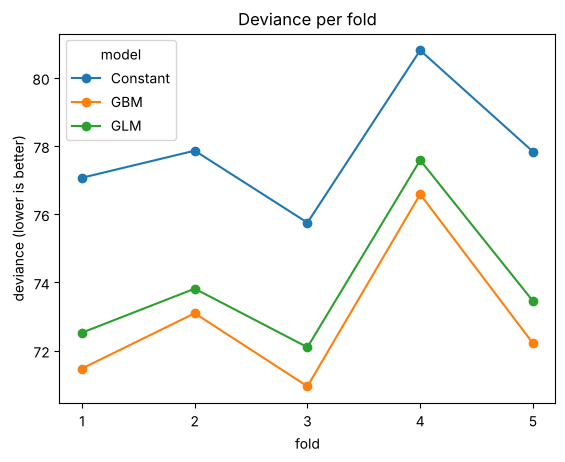

In [7]:
# mean and standard deviation over the five folds
summary = results.groupby("model", sort=False)[["deviance", "D2", "gini", "predicted/actual"]].agg(["mean", "std"])
print(summary.round(4), "\n")

# deviance per fold: is the ranking the same in every fold?
per_fold = results.pivot(index="fold", columns="model", values="deviance")
print(per_fold.round(3))
print("GBM better than GLM in", (per_fold["GBM"] < per_fold["GLM"]).sum(), "of 5 folds")

per_fold.plot(marker="o")
plt.xticks(per_fold.index)
plt.ylabel("deviance (lower is better)")
plt.title("Deviance per fold")
plt.show()

**Findings**

| model (mean of 5 folds) | deviance | D² | Gini | predicted / actual |
|---|---|---|---|---|
| Constant | 77.869 | −0.03 % | – | 1.002 |
| GLM | 73.899 | 5.08 % | 0.315 | 1.002 |
| GBM | **72.868** | **6.40 %** | **0.343** | 1.000 |

* Both models are clearly better than the constant.
* **The GBM has the lower deviance in all five folds** (by 0.72 to 1.24) and sorts the customers better (Gini 0.343
  against 0.315). The deviance varies between the folds (standard deviation about 2.2) because the folds themselves
  differ, as the constant model shows (1.85); the paired comparison within each fold is what counts, and there the GBM
  wins every time.
* All models get the overall level right (predicted / actual 1.000 to 1.002).

By accuracy alone, the GBM would be chosen. The next section checks the calibration by group.

### 5.2 Fairness: Zahlt jede Gruppe, was sie kostet?

             claim_rows    GLM    GBM
DrivAgeBand                          
18-20               502  0.998  1.284
21-24              1132  0.999  1.108
25-29              1810  1.015  0.967
30-39              4586  1.006  0.991
40-49              5218  0.995  0.965
50-59              4506  0.986  0.975
60-69              1946  1.015  0.950
70+                1446  1.000  1.138 

                claim_rows    GLM    GBM
BonusMalusBand                          
50                    9229  1.001  0.976
51-60                 2851  1.008  0.999
61-70                 2493  0.999  0.928
71-80                 2257  1.003  1.065
81-90                 1366  0.981  1.015
91-100                1942  1.007  1.121
101+                  1008  0.975  1.000 

            claim_rows    GLM    GBM
VehAgeBand                          
0-4               7539  0.999  1.011
5-9               6413  0.993  0.992
10-14             5189  1.006  0.983
15-19             1748  1.003  1.054
20+                257  1

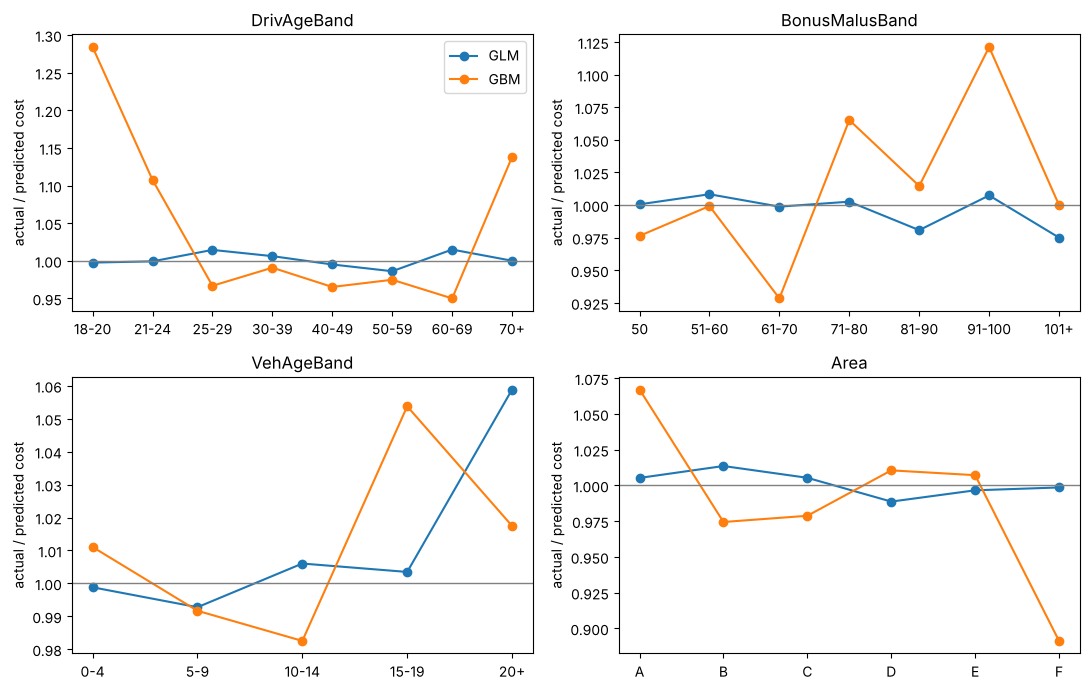

In [8]:
# actual / predicted cost per group, with the out-of-fold predictions (1.0 = the group pays exactly what it costs)
check = train[["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "Area", "claim_rows", "ClaimAmountCapped"]].copy()
for m in ["GLM", "GBM"]:
    check["cost_" + m] = oof[m] * train["Exposure"]      # predicted cost of every contract

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, ["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "Area"]):
    g = check.groupby(col, observed=True)[["claim_rows", "ClaimAmountCapped", "cost_GLM", "cost_GBM"]].sum()
    g["GLM"] = g["ClaimAmountCapped"] / g["cost_GLM"]
    g["GBM"] = g["ClaimAmountCapped"] / g["cost_GBM"]
    print(g[["claim_rows", "GLM", "GBM"]].round(3), "\n")
    ax.plot(g.index.astype(str), g["GLM"], marker="o", label="GLM")
    ax.plot(g.index.astype(str), g["GBM"], marker="o", label="GBM")
    ax.axhline(1, color="grey", lw=1)
    ax.set_title(col)
    ax.set_ylabel("actual / predicted cost")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [9]:
# the same by price group: contracts sorted by their predicted premium and cut into ten groups of equal size
for m in ["GLM", "GBM"]:
    decile = pd.qcut(oof[m].rank(method="first"), 10, labels=range(1, 11))
    g = check.groupby(decile, observed=True)[["ClaimAmountCapped", "cost_" + m]].sum()
    print(m, "actual / predicted, cheapest to most expensive group:", (g["ClaimAmountCapped"] / g["cost_" + m]).round(2).tolist())

GLM actual / predicted, cheapest to most expensive group: [1.19, 1.11, 0.96, 1.03, 1.08, 0.96, 1.04, 0.92, 0.97, 0.97]
GBM actual / predicted, cheapest to most expensive group: [1.29, 1.06, 1.0, 0.98, 0.84, 0.94, 0.97, 0.99, 0.95, 1.05]


**Findings** (actual / predicted cost on unseen data; 1.00 = the group pays exactly what it costs)

* **GLM:** every age band, Bonus-Malus band, vehicle-age band and area lies between 0.975 and 1.059, all except
  vehicle age 20+ (257 claims, 1.059) within ±2.5 %. These groups are the GLM's own factors, so this is expected: for the
  frequency part, the maximum-likelihood equations make every factor reproduce the claims of its group on the fitting
  data. The check shows that this also holds on unseen data.
* **GBM:** the youngest drivers cost 1.284 times what the GBM charges them (18–20, 502 claims), drivers aged 70+ 1.138
  times and the Bonus-Malus band 91–100 1.121 times. Bonus-Malus 61–70 (0.928) and area F (0.891) are charged too much.
  A possible reason for the young drivers (a hypothesis, not tested here): the minimum leaf sizes and early stopping
  let a small group move only a little away from the average.
* **Price groups** (contracts sorted by their own predicted premium): GLM 0.92–1.19, GBM 0.84–1.29. Both models are
  too cheap for the cheapest tenth of the customers, the GLM less so (1.19 against 1.29). The GBM is too expensive in
  the middle group 5 (0.84).

### 5.3 Entscheidung

**Decision: the GLM (Poisson × Gamma) becomes the final model; the GBM stays as the benchmark.**

* **Accuracy:** the GBM is better in every fold (deviance 72.868 against 73.899, D² 6.40 % against 5.08 %, Gini 0.343
  against 0.315).
* **Fairness:** the GLM prices every age, Bonus-Malus and vehicle-age band and every area close to its actual cost. The
  GBM does not: the actual cost of the youngest drivers is 28 % above their GBM premium, so the other customers would
  pay for them. The goal is a fair premium per customer, so by the decision rule of section 3 the calibration
  decides here.
* **Transparency:** the GLM is a table of factors that an actuary, a supervisor or a customer adviser can read and check;
  the GBM is not.
* **The price of this decision:** a deviance higher by about 1.0 (73.899 against 72.868) and a lower Gini. The GBM shows
  that the GLM misses some structure (finer shapes within the bands, interactions between features). Using the GBM to
  find this structure and adding it to the GLM is the first improvement idea in step 4.
* Both models are too cheap for the cheapest tenth of the customers; this stays a limitation of the final model.

## 6. Zusammenfassung

* **Candidates:** constant, GLM (Poisson × Gamma) and gradient boosting (Poisson × Gamma), all as frequency × severity
  on capped claims, with exposure as weight.
* **Metric:** exposure-weighted Tweedie deviance (power 1.5) on unseen data, plus D², Gini and calibration by group.
  The deviance decides between equally well calibrated models.
* **Procedure:** 5-fold cross-validation on the training part, the same folds for every model; the test part is not
  used.
* **Result:** the GBM is more accurate in every fold (D² 6.40 % against 5.08 %), but it charges the youngest drivers
  far too little (their actual cost is 1.28 times their premium); the GLM is within ±2.5 % in every band of the four checked variables (age, Bonus-Malus, vehicle age,
  area), except vehicle age 20+ (1.059).
* **Decision:** the GLM is the final model, the GBM the benchmark.

**Hand-over to step 4:** fit the GLM on the whole training part, evaluate it once on the test part (against the GBM),
show which variables and factors matter, add the large-claim loading and compute the premium of every customer.